# Phase 0 Spike — Do text embeddings carry diffusion signal?

**Question (H1/H2):** Are technologies with similar descriptions also similar in their diffusion
dynamics, and does a k-nearest-analog prior on embeddings beat naive baselines?

**Decision rule (concept §7), evaluated on log q:**
- Mantel test embedding distance vs. |Δ log q|, one-sided p < 0.05
- kNN-on-embeddings LOO error significantly lower than global mean and random analogs (Holm-adjusted p < 0.05)
- Positive control detects planted signal, negative control (permuted texts) does not
- GO if additionally better than TF-IDF, SOFT GO otherwise, NO-GO if the first two fail

Pipeline: OWID curves → Bass fits (anchored at first observation) → targets (log p, log q, T₁₀→₉₀)
→ Wikipedia descriptions with leakage masking → embeddings → tests → controls → verdict.

In [1]:
from __future__ import annotations

import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))

import spike_lib as sl

from adoptsim.data import (
    load_descriptions,
    load_owid_us_households,
    make_synthetic_dataset,
    mask_leakage,
    prepare_curves,
)
from adoptsim.models import bass_cumulative

pd.set_option("display.width", 140)
pd.set_option("display.precision", 3)

## 0. Configuration

In [2]:
CONFIG = {
    "source": "owid",  # "owid" | "synthetic"
    "allow_synthetic_fallback": True,
    "primary_encoder": "sentence:sentence-transformers/all-MiniLM-L6-v2",
    "extra_encoders": ["sentence:BAAI/bge-small-en-v1.5"],  # set [] to skip
    "k": 5,  # Goodwin et al. (2013): little gain beyond 5-6 analogs
    "min_points": 8,
    "min_peak": 0.15,
    "min_r2": 0.95,
    "n_sentences": 2,  # description truncation for leakage control
    "n_perm": 9999,
    "seed": 0,
}
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "experiments" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(CONFIG["seed"])

## 1. Adoption curves

In [3]:
IS_SYNTHETIC = CONFIG["source"] == "synthetic"
if not IS_SYNTHETIC:
    try:
        raw = load_owid_us_households(DATA_DIR / "raw")
    except Exception as exc:  # network or schema problems
        if not CONFIG["allow_synthetic_fallback"]:
            raise
        warnings.warn(
            f"OWID download failed ({exc!r}). Falling back to SYNTHETIC data: results are a "
            "pipeline check only, NOT a go/no-go decision. Download the CSV manually into "
            "data/raw/ or pass path= to load_owid_us_households().",
            stacklevel=1,
        )
        IS_SYNTHETIC = True
if IS_SYNTHETIC:
    raw, syn_desc, syn_truth = make_synthetic_dataset(n=40, signal=0.6, seed=CONFIG["seed"])

src_name = "synthetic" if IS_SYNTHETIC else "owid"
print(f"source={src_name}  technologies={raw.technology.nunique()}  rows={len(raw)}")
curves = prepare_curves(raw, min_points=CONFIG["min_points"], min_peak=CONFIG["min_peak"])
print(f"usable after truncation/filters: {curves.technology.nunique()}")

source=owid  technologies=45  rows=1395
usable after truncation/filters: 32


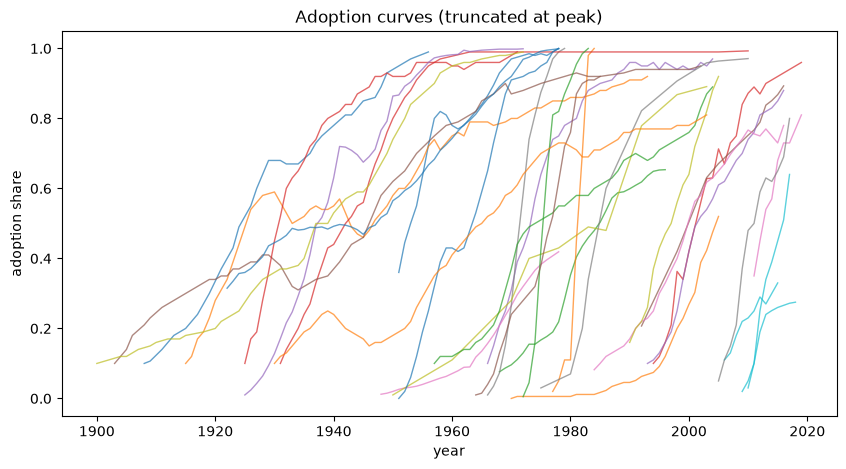

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for _tech, g in curves.groupby("technology"):
    ax.plot(g.year, g.adoption, lw=1, alpha=0.7)
ax.set(xlabel="year", ylabel="adoption share", title="Adoption curves (truncated at peak)")
plt.show()

## 2. Bass fits

Each curve is fitted with the closed form anchored at its first observation, so no unobserved
launch year is estimated. Poor fits (R² below threshold) are excluded: their parameters would
inject noise into the targets rather than diffusion signal.

In [5]:
fits_all = sl.fit_all(curves)
fits = fits_all[fits_all.r2 >= CONFIG["min_r2"]].reset_index(drop=True)
print(f"fitted={len(fits_all)}  kept (R²>={CONFIG['min_r2']})={len(fits)}")
fits.sort_values("q")[["technology", "first_year", "n_obs", "p", "q", "m", "r2", "takeoff_10_90"]]

fitted=32  kept (R²>=0.95)=28


,technology,first_year,n_obs,p,q,m,r2,takeoff_10_90
16,Podcasting,2006,10,1.239e-01,1.000e-04,0.422,0.972,17.723
20,Radio,1925,47,9.728e-02,1.400e-02,0.990,0.992,20.710
10,Home air conditioning,1957,48,1.504e-02,5.787e-02,0.890,0.964,46.185
25,Stove,1900,73,1.000e-06,6.321e-02,1.000,0.953,69.519
27,Washing machine,1930,74,1.000e-06,6.586e-02,0.875,0.960,66.722
3,Computer,1992,11,3.517e-02,6.693e-02,1.000,0.991,29.589
26,Tablet,2010,8,1.025e-01,7.426e-02,1.000,0.983,14.878
6,Dryer,1950,10,5.881e-03,7.728e-02,1.000,0.960,47.016
8,Electric power,1908,49,9.570e-03,8.472e-02,1.000,0.985,39.843
21,Refrigerator,1925,48,2.301e-02,1.228e-01,1.000,0.989,24.191


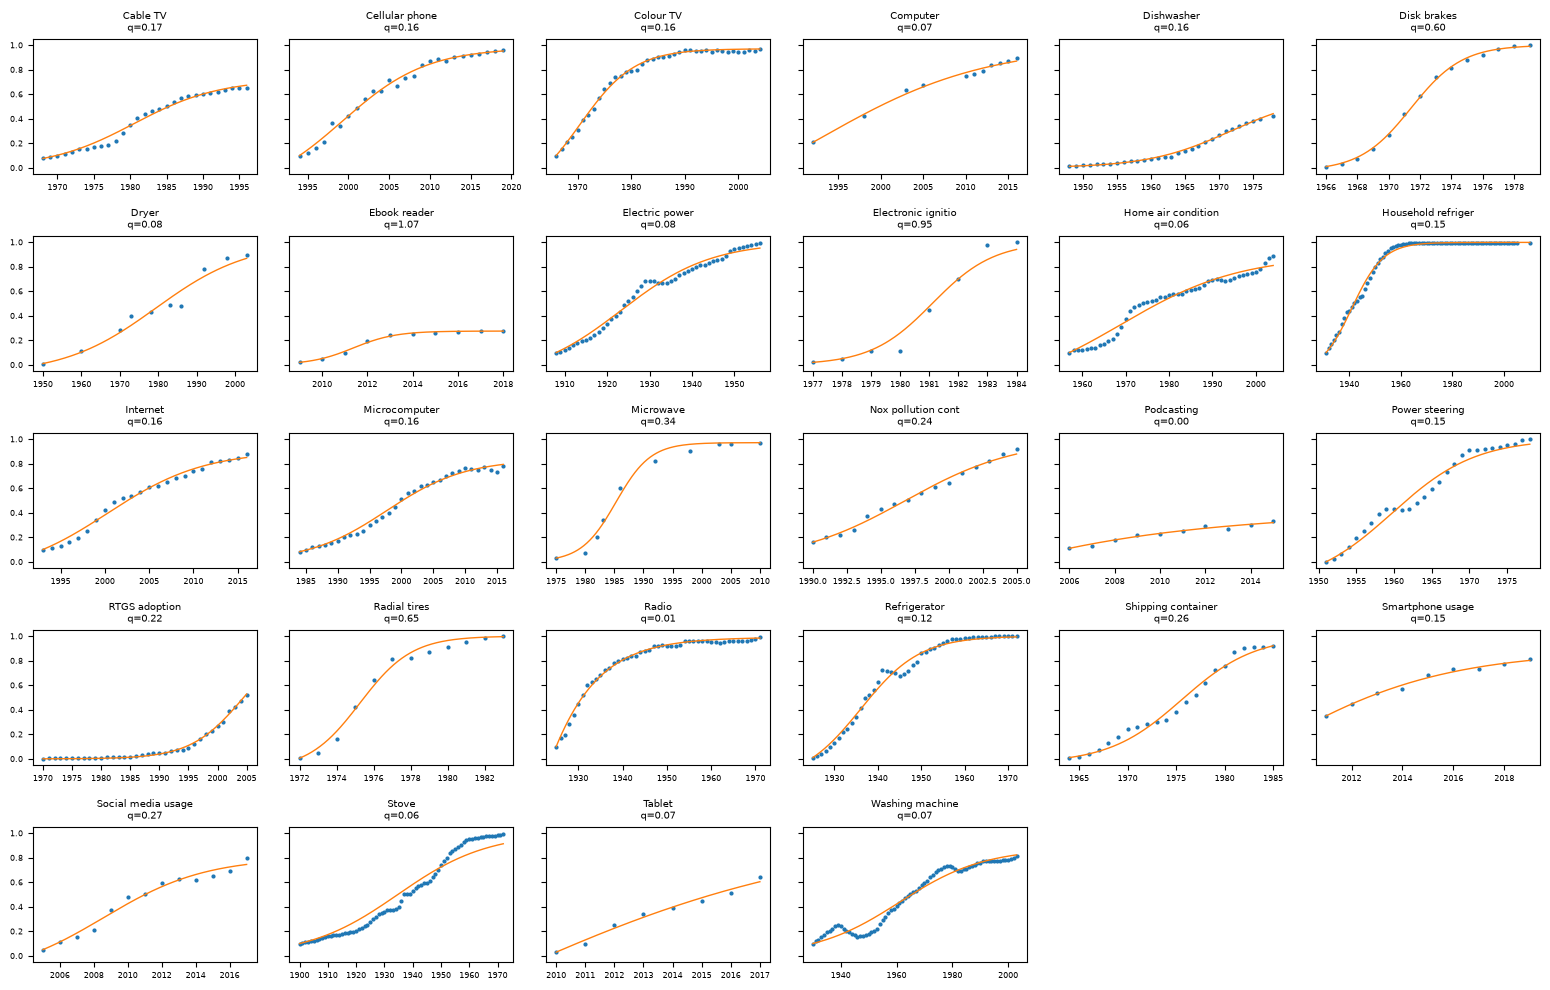

In [6]:
n = len(fits)
cols = 6
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.0 * rows), sharey=True, squeeze=False)
for ax, r in zip(axes.flat, fits.itertuples(), strict=False):
    g = curves[curves.technology == r.technology]
    t = np.linspace(g.year.min(), g.year.max(), 200)
    n0 = g.adoption.iloc[0]
    ax.plot(g.year, g.adoption, "o", ms=2)
    ax.plot(t, bass_cumulative(t, r.p, r.q, r.m, g.year.min(), n0), lw=1)
    ax.set_title(f"{r.technology[:18]}\nq={r.q:.2f}", fontsize=7)
    ax.tick_params(labelsize=6)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

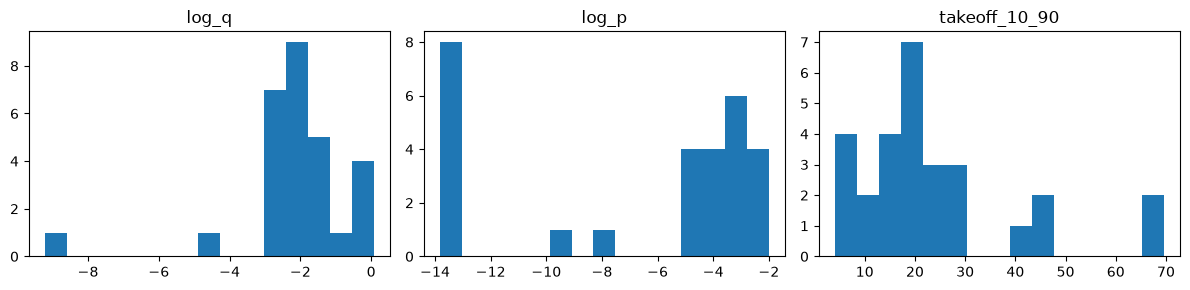

               log_q  log_p  takeoff_10_90
log_q          1.000 -0.298         -0.668
log_p         -0.298  1.000         -0.356
takeoff_10_90 -0.668 -0.356          1.000


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, sl.TARGETS, strict=True):
    ax.hist(fits[col], bins=15)
    ax.set_title(col)
plt.tight_layout()
plt.show()
print(fits[list(sl.TARGETS)].corr(method="spearman"))

## 3. Descriptions and leakage control

Present-day Wikipedia summaries describe how successful a technology became. We keep the first
sentences (definition) and mask years, numbers and outcome vocabulary. Section 7 compares
masked vs. unmasked text: a large drop would indicate the unmasked signal was leakage.

In [8]:
names = fits.technology.tolist()
if IS_SYNTHETIC:
    desc = syn_desc.set_index("technology").loc[names].reset_index()
else:
    desc = load_descriptions(
        names,
        cache_path=DATA_DIR / "interim" / "descriptions.csv",
        title_overrides=DATA_DIR / "external" / "wikipedia_titles.csv",
        manual_path=DATA_DIR / "external" / "descriptions_manual.csv",
    )
missing = desc[desc.description.str.len() == 0].technology.tolist()
if missing:
    print("Missing descriptions (curate data/external/*):", missing)

keep = desc.description.str.len() > 0
fits = fits[fits.technology.isin(desc[keep].technology)].reset_index(drop=True)
desc = desc[keep].set_index("technology").loc[fits.technology].reset_index()
names = fits.technology.tolist()
texts_raw = desc.description.tolist()
texts = (
    [mask_leakage(t, n_sentences=CONFIG["n_sentences"]) for t in texts_raw]
    if not IS_SYNTHETIC
    else texts_raw
)
print(f"technologies with text: {len(names)}")
pd.DataFrame({"technology": names, "masked": texts}).head(10)

Missing descriptions (curate data/external/*): ['Nox pollution controls (boilers)']
technologies with text: 27


,technology,masked
0,Cable TV,Cable television is a system for delivering br...
1,Cellular phone,A mobile phone or cell phone is a portable wir...
2,Colour TV,Color television or colour television is a tel...
3,Computer,"A personal computer, or simply computer, is a ..."
4,Dishwasher,A dishwasher is a machine that is used to clea...
5,Disk brakes,A disc brake is a type of brake that uses the ...
6,Dryer,A clothes dryer is a powered appliance that is...
7,Ebook reader,"An e-reader, also called an e reader or e devi..."
8,Electric power,Electrification is the process of powering by ...
9,Electronic ignition,Ignition systems are used by heat engines to i...


## 4. Embeddings

In [9]:
embeddings: dict[str, np.ndarray] = {}
for kind in [CONFIG["primary_encoder"], *CONFIG["extra_encoders"], "tfidf"]:
    emb, name = sl.try_encode(kind, texts)
    if emb is not None:
        embeddings[name] = emb
PRIMARY = CONFIG["primary_encoder"] if CONFIG["primary_encoder"] in embeddings else "tfidf"
if CONFIG["primary_encoder"] != PRIMARY:
    warnings.warn(
        "Primary transformer encoder unavailable; verdict uses TF-IDF. "
        "Install with: uv sync --extra embeddings",
        stacklevel=1,
    )
print("encoders:", list(embeddings), "| primary:", PRIMARY)

C:\Users\Vanessa Bubu Schmidt\Desktop\Utils\dev\innovation-adoption-simulator\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3612.24it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2222.19it/s]

encoders: ['sentence:sentence-transformers/all-MiniLM-L6-v2', 'sentence:BAAI/bge-small-en-v1.5', 'tfidf'] | primary: sentence:sentence-transformers/all-MiniLM-L6-v2


In [10]:
sl.top_analogs(embeddings[PRIMARY], names, n=3).head(20)

,technology,analog_1,analog_2,analog_3
0,Cable TV,Colour TV (0.51),Radio (0.41),Internet (0.31)
1,Cellular phone,Smartphone usage (0.69),Tablet (0.31),Radio (0.31)
2,Colour TV,Cable TV (0.51),Radio (0.30),Microwave (0.23)
3,Computer,Microcomputer (0.59),Tablet (0.48),Internet (0.41)
4,Dishwasher,Washing machine (0.54),Stove (0.40),Dryer (0.37)
5,Disk brakes,Tablet (0.22),Dishwasher (0.22),Radial tires (0.20)
6,Dryer,Washing machine (0.63),Dishwasher (0.37),Microcomputer (0.27)
7,Ebook reader,Smartphone usage (0.43),Tablet (0.41),Computer (0.29)
8,Electric power,Power steering (0.34),Cable TV (0.25),Electronic ignition (0.24)
9,Electronic ignition,Stove (0.37),Electric power (0.24),Power steering (0.21)


## 5. H1 — Mantel test and H2 — leave-one-out analog prior

For every target: Spearman Mantel correlation between embedding cosine distance and target
distance (one-sided permutation test), then LOO absolute errors of the kNN analog mean versus
global mean, random analogs and the other encoders. Paired sign-flip tests, Holm-adjusted per target.

In [11]:
suite = sl.run_suite(embeddings, fits, k=CONFIG["k"], n_perm=CONFIG["n_perm"], seed=CONFIG["seed"])
suite.mantel

,target,encoder,r,p
0,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,0.109,0.148
1,log_q,sentence:BAAI/bge-small-en-v1.5,0.212,0.030
2,log_q,tfidf,-0.028,0.641
3,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,0.017,0.341
4,log_p,sentence:BAAI/bge-small-en-v1.5,0.063,0.133
5,log_p,tfidf,-0.050,0.816
6,takeoff_10_90,sentence:sentence-transformers/all-MiniLM-L6-v2,0.044,0.292
7,takeoff_10_90,sentence:BAAI/bge-small-en-v1.5,0.110,0.129
8,takeoff_10_90,tfidf,-0.035,0.669


In [12]:
suite.errors.pivot(index="method", columns="target", values="mae")

target,log_p,log_q,takeoff_10_90
method,,,
global_mean,4.528,1.010,12.640
random_analogs,4.600,1.179,13.956
sentence:BAAI/bge-small-en-v1.5,4.597,1.155,11.849
sentence:sentence-transformers/all-MiniLM-L6-v2,4.325,1.109,12.196
tfidf,4.797,1.272,13.649


In [13]:
suite.tests.query("model == @PRIMARY")

,target,model,baseline,mae_gain,p,p_holm
0,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,global_mean,-0.099,0.791,1.000
1,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,random_analogs,0.070,0.285,1.000
2,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,sentence:BAAI/bge-small-en-v1.5,0.046,0.336,1.000
3,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,tfidf,0.162,0.179,1.000
12,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,global_mean,0.204,0.279,1.000
13,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,random_analogs,0.275,0.212,1.000
14,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,sentence:BAAI/bge-small-en-v1.5,0.272,0.215,1.000
15,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,tfidf,0.473,0.105,1.000
24,takeoff_10_90,sentence:sentence-transformers/all-MiniLM-L6-v2,global_mean,0.444,0.380,1.000
25,takeoff_10_90,sentence:sentence-transformers/all-MiniLM-L6-v2,random_analogs,1.760,0.093,0.909


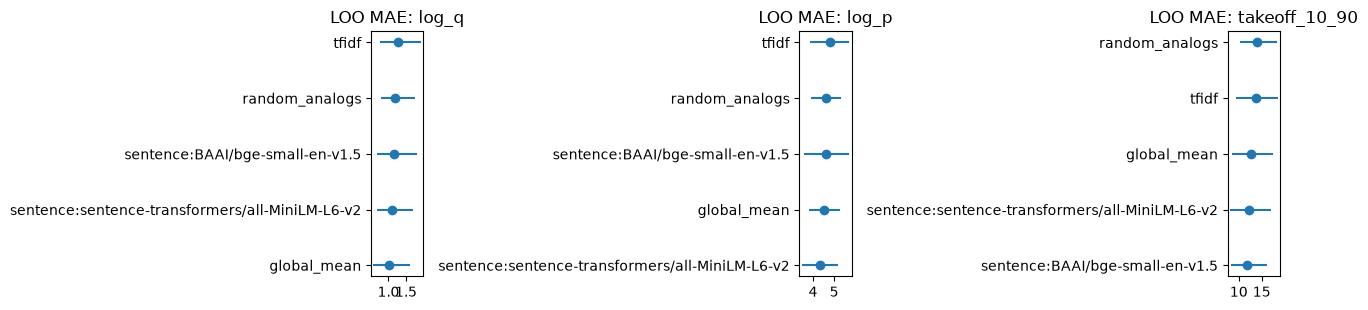

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, target in zip(axes, sl.TARGETS, strict=True):
    e = suite.errors[suite.errors.target == target].sort_values("mae")
    ax.errorbar(e.mae, e.method, xerr=[e.mae - e.ci_lo, e.ci_hi - e.mae], fmt="o")
    ax.set_title(f"LOO MAE: {target}")
plt.tight_layout()
plt.show()

## 6. Controls

- **Negative control:** permute descriptions across technologies. The Mantel p-value should be
  roughly uniform; we report the share of permutations with p < 0.05 (expected ≈ 0.05).
- **Positive control:** synthetic dataset with planted text signal of the same size as the real
  dataset. The pipeline must detect it, otherwise a null result on real data is uninformative.

In [15]:
from adoptsim.evaluation import cosine_distance_matrix, mantel_test

y = fits["log_q"].to_numpy()
d_y = np.abs(y[:, None] - y[None, :])
neg_p = []
for i in range(50):
    perm = rng.permutation(len(texts))
    emb_perm = embeddings[PRIMARY][perm]
    neg_p.append(mantel_test(cosine_distance_matrix(emb_perm), d_y, n_perm=999, seed=i).p_value)
neg_rate = float(np.mean(np.array(neg_p) < 0.05))
print(f"negative control: share p<0.05 = {neg_rate:.2f} (expected ~0.05)")

_, pos_desc, pos_truth = make_synthetic_dataset(n=max(len(names), 20), signal=0.6, seed=123)
pos_emb, _ = sl.try_encode(PRIMARY, pos_desc.description.tolist())
pos_y = np.log(pos_truth.q.to_numpy())
pos = mantel_test(
    cosine_distance_matrix(pos_emb), np.abs(pos_y[:, None] - pos_y[None, :]), n_perm=1999
)
print(f"positive control (n={len(pos_y)}): r={pos.statistic:.3f}, p={pos.p_value:.4f}")
controls_ok = neg_rate <= 0.15 and pos.p_value < 0.05
print("controls ok:", controls_ok)

negative control: share p<0.05 = 0.04 (expected ~0.05)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2330.12it/s]

positive control (n=27): r=0.646, p=0.0005
controls ok: True


## 7. Sensitivity analyses

- **Leakage:** unmasked vs. masked text (real data only).
- **Temporal:** only technologies whose series started earlier may serve as analogs —
  the realistic pre-launch setting.

In [16]:
sens = {}
if not IS_SYNTHETIC:
    emb_raw, _ = sl.try_encode(PRIMARY, texts_raw)
    if emb_raw is not None:
        s_raw = sl.run_suite({PRIMARY: emb_raw}, fits, k=CONFIG["k"], n_perm=1999)
        cmp = s_raw.mantel.merge(
            suite.mantel[suite.mantel.encoder == PRIMARY],
            on=["target", "encoder"],
            suffixes=("_unmasked", "_masked"),
        )
        sens["leakage"] = cmp.to_dict(orient="records")
        display(cmp)

first = fits.first_year.to_numpy()
allowed = first[None, :] < first[:, None]  # j launched before i
s_tmp = sl.run_suite(embeddings, fits, k=CONFIG["k"], allowed=allowed, n_perm=1999)
sens["temporal_errors"] = s_tmp.errors.to_dict(orient="records")
s_tmp.errors.pivot(index="method", columns="target", values="mae")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2859.41it/s]

,target,encoder,r_unmasked,p_unmasked,r_masked,p_masked
0,log_q,sentence:sentence-transformers/all-MiniLM-L6-v2,0.040,0.329,0.109,0.148
1,log_p,sentence:sentence-transformers/all-MiniLM-L6-v2,0.061,0.133,0.017,0.341
2,takeoff_10_90,sentence:sentence-transformers/all-MiniLM-L6-v2,0.021,0.363,0.044,0.292


target,log_p,log_q,takeoff_10_90
method,,,
global_mean,5.010,1.037,16.951
random_analogs,5.045,1.099,17.378
sentence:BAAI/bge-small-en-v1.5,5.152,1.170,15.808
sentence:sentence-transformers/all-MiniLM-L6-v2,4.842,1.161,16.928
tfidf,5.040,1.141,16.203


## 8. Verdict

In [17]:
decision = sl.go_no_go(suite, PRIMARY)
decision["controls_ok"] = controls_ok
decision["n_technologies"] = len(names)
decision["source"] = "synthetic" if IS_SYNTHETIC else "owid"
if IS_SYNTHETIC:
    decision["verdict"] = f"PIPELINE CHECK ONLY (synthetic) — would be {decision['verdict']}"
elif not controls_ok:
    decision["verdict"] = f"INCONCLUSIVE (controls failed) — raw {decision['verdict']}"
for k_, v_ in decision.items():
    print(f"{k_:>30}: {v_}")

out = {
    "config": CONFIG,
    "decision": decision,
    "mantel": suite.mantel.to_dict(orient="records"),
    "errors": suite.errors.to_dict(orient="records"),
    "tests": suite.tests.to_dict(orient="records"),
    "sensitivity": sens,
    "fits": fits.to_dict(orient="records"),
}
path = RESULTS_DIR / f"spike_v0_{decision['source']}.json"
path.write_text(json.dumps(out, indent=2, default=float))
print("saved", path.relative_to(ROOT))

               primary_encoder: sentence:sentence-transformers/all-MiniLM-L6-v2
                mantel_log_q_p: 0.1485
      beats_global_mean_p_holm: 1.0
   beats_random_analogs_p_holm: 1.0
            beats_tfidf_p_holm: 1.0
                       verdict: NO-GO
                   controls_ok: True
                n_technologies: 27
                        source: owid
saved experiments\results\spike_v0_owid.json


## Notes and next steps

- n is small (OWID ≈ 30–40 curves): treat effect sizes and CIs as indicative. A GO here licenses
  phase 2 data work (CHAT country curves, historical Wikipedia revisions), not a final claim.
- Several OWID series are not household shares (e.g. share of cars with disc brakes); consider
  an `unit` annotation and excluding non-household series in a robustness run.
- Survivorship bias: all curves are successful technologies; predictions are conditional on success.